In [ ]:
from pathlib import Path
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import sys

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

In [11]:
ROOT_DIR = Path.cwd().parent

DATA_PATH =ROOT_DIR / "notebooks" / "churn_preprocessed.csv"
MODEL_PATH = ROOT_DIR / "models" / "churn_model.joblib"
FIGURES_DIR = ROOT_DIR / "reports" / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [12]:
df = pd.read_csv(DATA_PATH)

X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 5634
Testing samples: 1409


In [24]:
model = joblib.load(MODEL_PATH)

# Predict churn probability using the loaded model
y_prob = model.predict_proba(X_test)[:, 1]
print("Number of probabilities:", len(y_prob))

# Use the same threshold
threshold = 0.7

# Convert probability to prediction
y_pred_threshold = (y_prob >= threshold).astype(int)

print("Predictions completed successfully!")

Number of probabilities: 1409
Predictions completed successfully!


In [25]:
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("Type of X_test:", type(X_test))
print("Type of y_test:", type(y_test))

print("y_prob shape:", y_prob.shape)

X_test shape: (1409, 19)
y_test shape: (1409,)
Type of X_test: <class 'pandas.DataFrame'>
Type of y_test: <class 'pandas.Series'>
y_prob shape: (1409,)


In [26]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_threshold),
    "Precision": precision_score(y_test, y_pred_threshold, zero_division=0),
    "Recall": recall_score(y_test, y_pred_threshold, zero_division=0),
    "F1-Score": f1_score(y_test, y_pred_threshold, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

metrics_df = pd.DataFrame(
    metrics.items(),
    columns=["Metric", "Score"]
)

metrics_df

,Metric,Score
0,Accuracy,0.790632
1,Precision,0.608219
2,Recall,0.593583
3,F1-Score,0.600812
4,ROC-AUC,0.840241


In [27]:
print(
    classification_report(
        y_test,
        y_pred_threshold,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

    No Churn       0.85      0.86      0.86      1035
       Churn       0.61      0.59      0.60       374

    accuracy                           0.79      1409
   macro avg       0.73      0.73      0.73      1409
weighted avg       0.79      0.79      0.79      1409



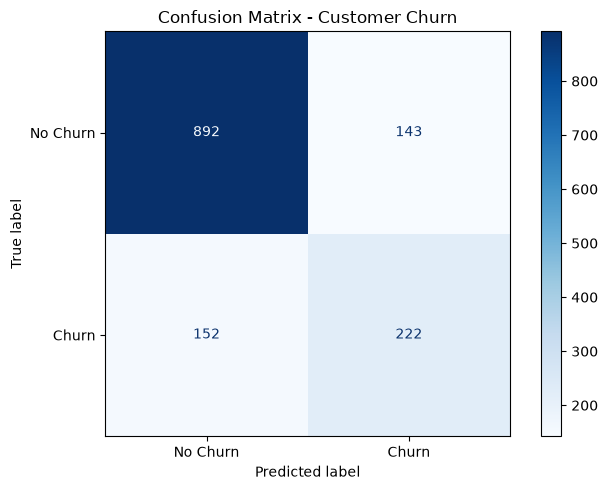

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_threshold,
    display_labels=["No Churn", "Churn"],
    cmap="Blues",
    ax=ax
)

ax.set_title("Confusion Matrix - Customer Churn")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "Confusion Matrix - Logistic Regression.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

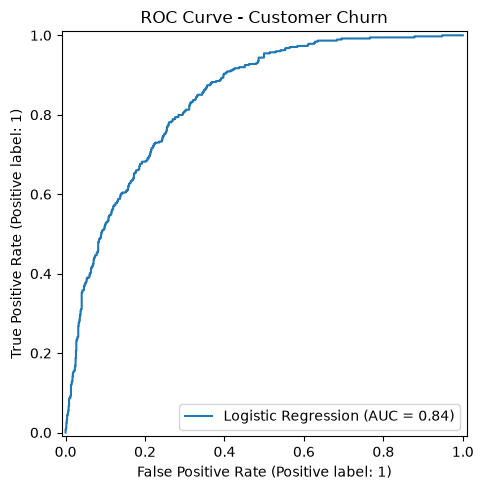

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    ax=ax,
    name="Logistic Regression"
)

ax.set_title("ROC Curve - Customer Churn")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "ROC Curve - Logistic Regression.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [32]:
metrics_df.to_csv(
    ROOT_DIR / "reports" / "evaluation_metrics.csv",
    index=False
)

report = classification_report(
    y_test,
    y_pred_threshold,
    target_names=["No Churn", "Churn"],
    output_dict=True,
    zero_division=0
)

with open(
    ROOT_DIR / "report" / "classification_report.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(report, file, indent=4)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!
